In [8]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [9]:
from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format


In [10]:
import os
from pathlib import Path

current_folder = Path.cwd()
dataset_folder = current_folder / "mnist-in-csv"

if not dataset_folder.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {dataset_folder}")

path = str(dataset_folder)
required_files = ["mnist_train.csv", "mnist_test.csv"]
missing_files = [filename for filename in required_files if not (dataset_folder / filename).is_file()]

if missing_files:
    raise FileNotFoundError(f"Missing dataset file(s): {', '.join(missing_files)}")

print("Using local dataset folder:", path)
print("Dataset files:")
for filename in required_files:
    print(filename)

Using local dataset folder: d:\UIU CSE\GitHub\Deep-learning\Computer Vision\mnist-in-csv
Dataset files:
mnist_train.csv
mnist_test.csv


In [11]:
train_file = os.path.join(path, "mnist_train.csv")
test_file = os.path.join(path, "mnist_test.csv")
df = pd.read_csv(train_file)
df_test= pd.read_csv(test_file)

In [12]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
df.shape

(60000, 785)

In [14]:
#pre-process
X_train = df.drop("label",axis=1).values
y_train = df['label'].values
X_test=df_test.drop('label',axis=1).values
y_test = df_test['label'].values

In [15]:
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

In [16]:
XtrainImage = X_train.reshape(-1,28,28)
XtestImage = X_test.reshape(-1,28,28)

In [17]:
y_train_cat= to_categorical(y_train,10)
ytestcat= to_categorical(y_test,10)

# First try perceptron model

In [18]:
perceptron= Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation='softmax')
])

In [19]:
perceptron.compile(optimizer='sgd',loss='categorical_crossentropy',metrics=['accuracy'])

In [39]:
history_percp=perceptron.fit(XtrainImage,y_train_cat ,epochs=5,
    batch_size=32,validation_data=(XtestImage, ytestcat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 951us/step - accuracy: 0.9041 - loss: 0.3480 - val_accuracy: 0.9107 - val_loss: 0.3281
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 920us/step - accuracy: 0.9063 - loss: 0.3390 - val_accuracy: 0.9124 - val_loss: 0.3211
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 964us/step - accuracy: 0.9078 - loss: 0.3318 - val_accuracy: 0.9138 - val_loss: 0.3156
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 968us/step - accuracy: 0.9096 - loss: 0.3260 - val_accuracy: 0.9140 - val_loss: 0.3111
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 918us/step - accuracy: 0.9107 - loss: 0.3211 - val_accuracy: 0.9151 - val_loss: 0.3073


In [21]:
accuracy_perceptron = perceptron.evaluate(XtestImage,ytestcat,verbose=0)[1]
accuracy_perceptron

0.9085999727249146

# Now lets try ANN

In [22]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])

In [23]:
ann.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])


In [24]:
ann_model= ann.fit(XtrainImage,y_train_cat, epochs=5,
                    batch_size=32, validation_data=(XtestImage,ytestcat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9275 - loss: 0.2469 - val_accuracy: 0.9612 - val_loss: 0.1189
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9693 - loss: 0.1016 - val_accuracy: 0.9723 - val_loss: 0.0861
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9786 - loss: 0.0704 - val_accuracy: 0.9721 - val_loss: 0.0838
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9845 - loss: 0.0505 - val_accuracy: 0.9763 - val_loss: 0.0751
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9880 - loss: 0.0387 - val_accuracy: 0.9760 - val_loss: 0.0812


In [25]:
acc_ann=ann.evaluate(XtestImage,ytestcat,verbose=0)[1]
acc_ann

0.9760000109672546

# Convolutional neural network

In [26]:
X_train_cnn = X_train.reshape(-1, 28, 28,1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [27]:
cnn = Sequential([
    Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPool2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation='relu'),
    MaxPool2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(10,activation='softmax')
])

In [28]:
cnn.compile(optimizer='adam',loss="categorical_crossentropy",metrics=['accuracy'])

In [29]:
cnn_model= cnn.fit(X_train_cnn,y_train_cat, epochs=5, validation_data=(X_test_cnn,ytestcat) 
                   , verbose=1)

Epoch 1/5


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9357 - loss: 0.2092 - val_accuracy: 0.9856 - val_loss: 0.0450
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9777 - loss: 0.0743 - val_accuracy: 0.9897 - val_loss: 0.0308
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9831 - loss: 0.0545 - val_accuracy: 0.9907 - val_loss: 0.0285
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9867 - loss: 0.0438 - val_accuracy: 0.9900 - val_loss: 0.0321
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9889 - loss: 0.0368 - val_accuracy: 0.9925 - val_loss: 0.0255


In [30]:
acc_cnn = cnn.evaluate(X_test_cnn,ytestcat, verbose=0)[1]
acc_cnn

0.9925000071525574

In [31]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

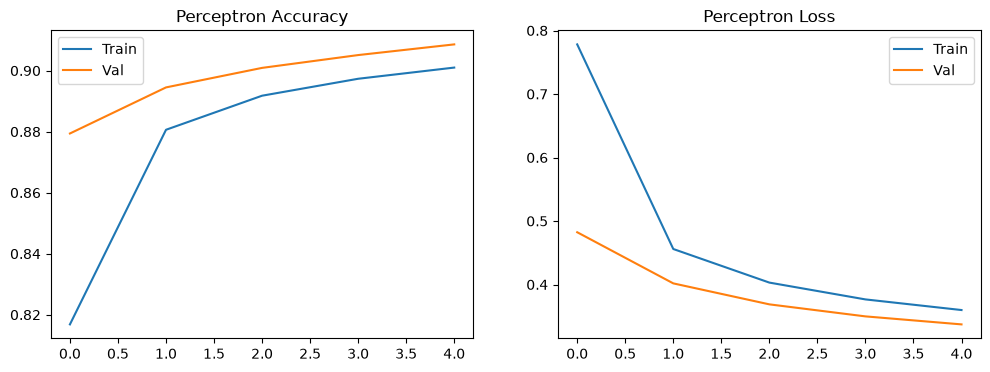

In [32]:
plot_training(history_percp, "Perceptron")

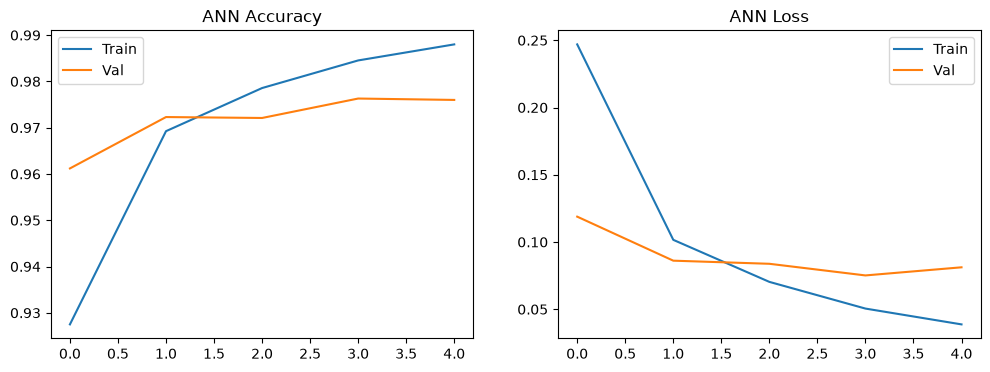

In [33]:
plot_training(ann_model, "ANN")

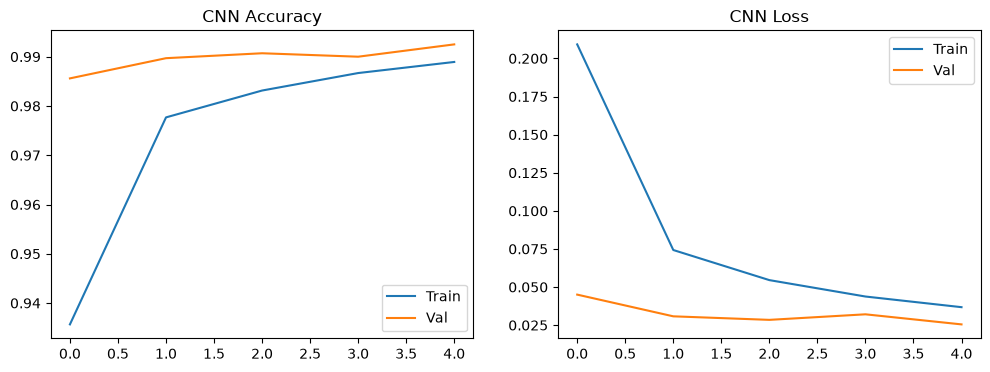

In [34]:
plot_training(cnn_model, "CNN")

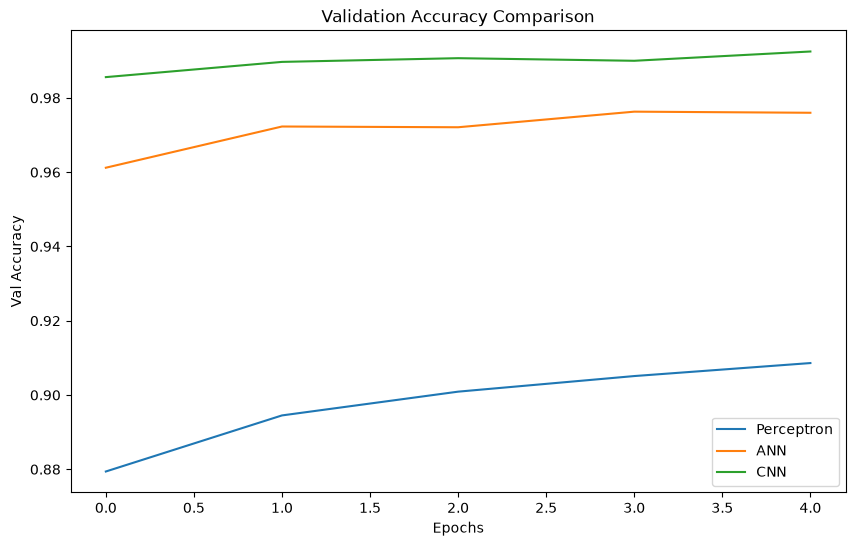

In [35]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(ann_model.history['val_accuracy'], label="ANN")
plt.plot(cnn_model.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [36]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


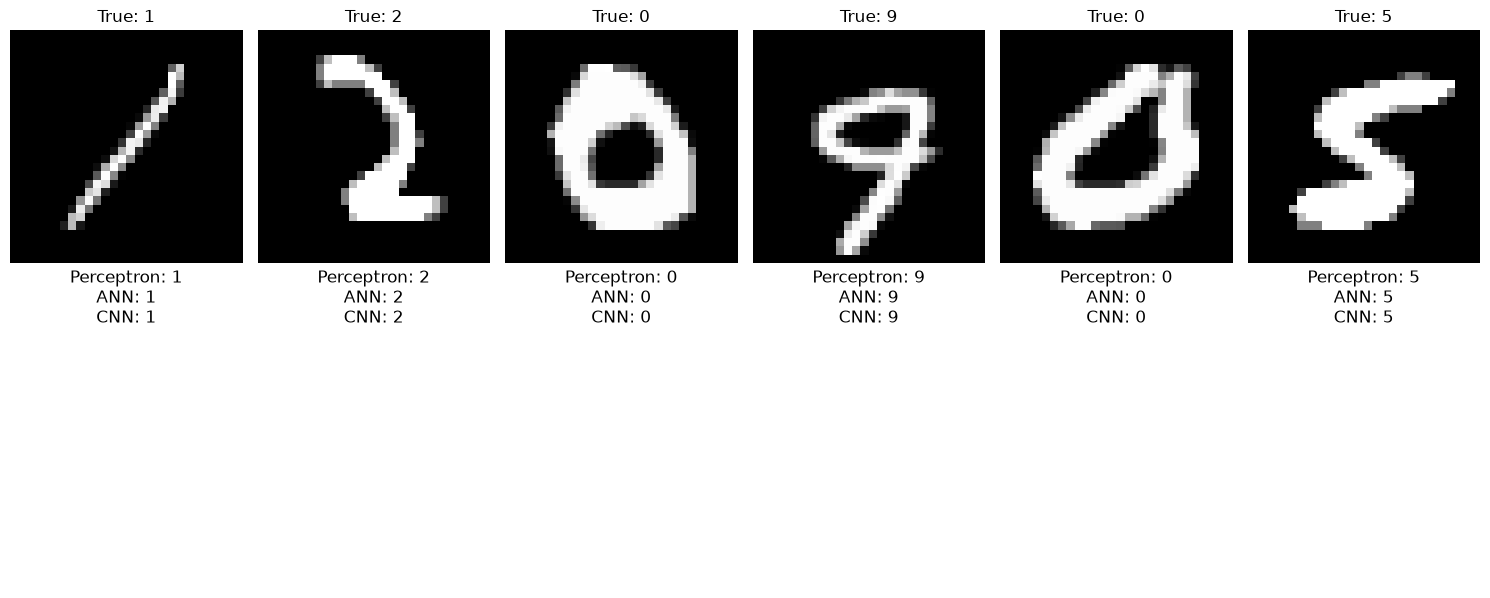

In [38]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], XtestImage, X_test_cnn, y_test, 6)